# Content-Based Recommendation with Classifiers

In the lecture a content-based recommender builds an *item profile* and a *user profile* and recommends the items whose features match the profile, using a hand-made similarity formula. In this lab the formula is replaced by **machine learning**: for each user we train a classifier that learns, from the movies this user has rated, which item features predict a *like*. The classifier's probability P(like | item features) is the predicted score, and we recommend the unseen movies with the highest score. The model's weights *are* the user profile.

In this laboratory we:

1. represent items by features that a classifier can use (multi-hot genres, release decade) and explain why a plain integer code for a category is a bad idea.
2. turn ratings into a per-user like/dislike training set and split it without leaking information.
3. train and compare four classifiers: logistic regression, naive Bayes, random forest and a small neural network.
4. evaluate a recommender with suitable metrics (ROC-AUC, precision@k) and compare it with simple baselines, instead of trusting accuracy alone.
5. explain a recommendation from the learned weights, and observe the cold-start problem with a learning curve.



The lab uses the **MovieLens "latest small"** dataset from GroupLens Research (University of Minnesota): about 100 000 ratings (0.5–5 stars) of about 9 700 movies by 610 users, with the genres of every movie and some free-text tags. Dataset page: <https://grouplens.org/datasets/movielens/latest/>.


In [1]:
import io
import re
import time
import urllib.request
import warnings
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import BernoulliNB
from sklearn.neural_network import MLPClassifier

SEED = 42
LIKE_THRESHOLD = 4.0   # a rating >= 4.0 stars is a "like"
MIN_RATINGS = 100      # we only model users with at least this many ratings

In [2]:
import io, ssl, zipfile, urllib.request
from pathlib import Path
import pandas as pd

URL = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"
DATA_DIR = Path("ml-latest-small")

if not (DATA_DIR / "ratings.csv").is_file():
    context = ssl._create_unverified_context()      # skips the certificate check
    with urllib.request.urlopen(URL, timeout=60, context=context) as response:
        zipfile.ZipFile(io.BytesIO(response.read())).extractall(".")

movies  = pd.read_csv(DATA_DIR / "movies.csv")
ratings = pd.read_csv(DATA_DIR / "ratings.csv")
tags    = pd.read_csv(DATA_DIR / "tags.csv")
print(movies.shape, ratings.shape, tags.shape)

movies.head()

(9742, 3) (100836, 4) (3683, 4)


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


## Part 1

Run the cell and read the output. It shows how many ratings there are, what the rating values look like, how many ratings a typical user gives, and how sparse the user–item matrix is.

In [3]:
n_users, n_movies = ratings["userId"].nunique(), ratings["movieId"].nunique()
print(f"movies in catalogue: {len(movies)} | rated movies: {n_movies} | users: {n_users} | ratings: {len(ratings)}")

print("\nRating values:")
print(ratings["rating"].value_counts().sort_index().to_string())

per_user = ratings.groupby("userId").size()
print("\nNumber of ratings per user:")
print(per_user.describe().round(1).to_string())

print(f"\nSparsity of the user-item matrix: {1 - len(ratings) / (n_users * n_movies):.3f}")
print(f"Share of ratings >= {LIKE_THRESHOLD}: {(ratings['rating'] >= LIKE_THRESHOLD).mean():.3f}")

movies in catalogue: 9742 | rated movies: 9724 | users: 610 | ratings: 100836

Rating values:
rating
0.5     1370
1.0     2811
1.5     1791
2.0     7551
2.5     5550
3.0    20047
3.5    13136
4.0    26818
4.5     8551
5.0    13211

Number of ratings per user:
count     610.0
mean      165.3
std       269.5
min        20.0
25%        35.0
50%        70.5
75%       168.0
max      2698.0

Sparsity of the user-item matrix: 0.983
Share of ratings >= 4.0: 0.482


**QUESTION 1.** What does the share of ratings above the like threshold tell you about a classifier that predicts "like" for every movie? Why do we model only users with at least `MIN_RATINGS` ratings?

**Your answer (Q1):**

About 48% of all ratings are ≥ 4.0, so likes and dislikes are roughly balanced across the whole dataset. A classifier that predicts "like" for every movie would therefore get about 48% accuracy. Predicting "dislike" for everything would get about 52%, and neither learns anything. This shows that accuracy alone does not tell us whether a model has learned anything useful. We must compare it with the majority-class baseline, and do that per user, because the like rate differs a lot between users. For a user who likes 80% of the movies they rated, always predicting "like" already gives 80% accuracy. That is why we also need metrics that judge the ranking rather than the 0.5 threshold, such as ROC-AUC and precision.


We model only users with at least MIN_RATINGS = 100 ratings because each user gets their own classifier, trained only on their own ratings. A typical user has about 70 ratings (the median), while there are several dozen features. With few ratings, the model has too few examples to learn from and overfits easily. After the 80/20 split, the test set would also be too small to compute AUC or precision@10 reliably, and one of the classes might be missing. The threshold avoids the cold-start problem but does not solve it: this recommender does not work for new users with only a few ratings.

## Part 2

A classifier needs numbers. MovieLens gives us only the title (which ends in the release year, for example `Toy Story (1995)`) and the genres (for example `Adventure|Animation|Children`). We build two kinds of features:

* **multi-hot genres** – one 0/1 column per genre; a movie can have several genres;
* **release decade** – one 0/1 column per decade (`decade_1990s`), plus `decade_unknown` for titles without a year.

### TASK 1 – Extract the release year

Implement `extract_year(title)`. The year is the four digits in parentheses at the **end** of the title. Titles can contain other parentheses (for example `City of Lost Children, The (Cité des enfants perdus, La) (1995)`). Return `np.nan` if there is no year. Hint: `re.search`.

In [4]:
def extract_year(title):
    # TODO: return the release year as a float, e.g. 1995.0, or np.nan if the title has no "(YYYY)" at its end.
    match = re.search(r"\((\d{4})\)\s*$", title)
    return float(match.group(1)) if match else np.nan

In [5]:
assert extract_year("Toy Story (1995)") == 1995
assert extract_year("City of Lost Children, The (Cité des enfants perdus, La) (1995)") == 1995
assert np.isnan(extract_year("A movie without a year"))
print("Task 1 OK")

Task 1 OK


### TASK 2 – Build the item feature matrix

Implement `build_item_features(movies)`. It returns a `DataFrame` with

* one row per movie, **indexed by `movieId`**, in the same order as `movies`;
* one column `genre_<Name>` per genre (value 1 if the movie has the genre, otherwise 0);
* one column `decade_<D>s` per decade, such as `decade_1990s`, and `decade_unknown` for movies without a year;
* only the integers 0 and 1.

Hints: `Series.str.get_dummies(sep="|")`, `pd.get_dummies`, and the decade of a year is `year // 10 * 10`.

In [6]:
def build_item_features(movies):
    # TODO: multi-hot genre columns + one-hot decade columns, indexed by movieId (see the description above).
    genres = movies["genres"].str.get_dummies(sep="|").add_prefix("genre_")

    years = movies["title"].map(extract_year)
    decades = (years // 10 * 10).map(lambda year: "unknown" if np.isnan(year) else f"{int(year)}s")
    decade_columns = pd.get_dummies(decades, prefix="decade", dtype=int)

    features = pd.concat([genres, decade_columns], axis=1)
    features.index = movies["movieId"]
    return features

In [7]:
toy_movies = pd.DataFrame({"movieId": [1, 2, 3],
                           "title": ["A (1995)", "B (1999)", "C"],
                           "genres": ["Comedy|Drama", "Drama", "(no genres listed)"]})
toy_features = build_item_features(toy_movies)

assert list(toy_features.index) == [1, 2, 3]
assert toy_features.loc[1, "genre_Comedy"] == 1 and toy_features.loc[1, "genre_Drama"] == 1
assert toy_features.loc[2, "genre_Comedy"] == 0
assert toy_features.loc[1, "decade_1990s"] == 1 and toy_features.loc[3, "decade_unknown"] == 1
assert set(np.unique(toy_features.values)) <= {0, 1}
print("Task 2 OK")

item_features = build_item_features(movies)
print("Feature matrix:", item_features.shape)
display(item_features.sum().sort_values(ascending=False).head(12).to_frame("movies"))

Task 2 OK
Feature matrix: (9742, 33)


,movies
genre_Drama,4361
genre_Comedy,3756
decade_2000s,2849
decade_1990s,2212
decade_2010s,1931
genre_Thriller,1894
genre_Action,1828
genre_Romance,1596
genre_Adventure,1263
genre_Crime,1199


## Part 3

The recommender is **personal**: every user gets their own classifier, trained only on the movies this user has rated. Rated movies with `rating >= LIKE_THRESHOLD` get the label 1 (like), the others 0 (dislike).

### TASK 3 – Build one user's dataset

Implement `get_user_data(ratings, item_features, user_id, like_threshold=LIKE_THRESHOLD)`. It returns `(X, y)`:

* `X` – the rows of `item_features` for the movies this user rated;
* `y` – a `Series` of 0/1 labels, indexed by `movieId` like `X` (same order).

In [8]:
def get_user_data(ratings, item_features, user_id, like_threshold=LIKE_THRESHOLD):
    # TODO: return (X, y) for one user, as described above.
    user_ratings = ratings[ratings["userId"] == user_id].set_index("movieId")
    X = item_features.loc[user_ratings.index]
    y = (user_ratings["rating"] >= like_threshold).astype(int)
    return X, y

In [9]:
toy_ratings = pd.DataFrame({"userId": [1, 1, 2], "movieId": [1, 2, 1], "rating": [4.5, 3.0, 2.0]})
X_toy, y_toy = get_user_data(toy_ratings, toy_features, user_id=1)

assert list(X_toy.index) == [1, 2] and list(y_toy.index) == [1, 2]
assert list(y_toy) == [1, 0]
assert X_toy.shape == (2, toy_features.shape[1])
print("Task 3 OK")

Task 3 OK


In [10]:
def eligible_users(ratings, min_ratings=MIN_RATINGS, like_threshold=LIKE_THRESHOLD, min_each_class=20):
    # users with enough ratings, and at least min_each_class likes AND dislikes (needed to train and to test)
    like = ratings["rating"] >= like_threshold
    stats = ratings.assign(like=like).groupby("userId")["like"].agg(["size", "sum"])
    ok = (stats["size"] >= min_ratings) & (stats["sum"] >= min_each_class) & \
         ((stats["size"] - stats["sum"]) >= min_each_class)
    return stats.index[ok].tolist()


users = eligible_users(ratings)
print(f"{len(users)} of {n_users} users are eligible")

237 of 610 users are eligible


## Part 4

### TASK 4 – Create the four models

Implement `make_model(kind, seed)` that returns an *untrained* scikit-learn classifier:

| `kind` | model |
|---|---|
| `"logreg"` | `LogisticRegression(max_iter=1000)` |
| `"naive_bayes"` | `BernoulliNB(alpha=1.0)` – the right naive Bayes variant for 0/1 features |
| `"random_forest"` | `RandomForestClassifier(n_estimators=100, min_samples_leaf=2, random_state=seed)` |
| `"neural_network"` | `MLPClassifier(hidden_layer_sizes=(16,), alpha=1e-2, max_iter=500, random_state=seed)` |

For any other `kind`, raise `ValueError`.

### TASK 5 – The recommender class

Implement the three methods of `ClassifierRecommender`:

* `fit(X, y)` – create the model with `make_model`, train it on `X.values` and `y.values`, store it in `self.model`, and return `self`.
* `predict_proba(X)` – return a 1-D NumPy array with the probability of the class **1 (like)** for every row of `X`. Do not assume that the column with the "like" probability is the second one: look at `self.model.classes_`.
* `recommend(item_features, seen_ids, titles, n=10)` – score all movies in `item_features` that are **not** in `seen_ids`, and return a `DataFrame` indexed by `movieId` with the columns `title` and `p_like`, sorted by `p_like` in descending order, with `n` rows. Sort in a stable way (`kind="mergesort"`) so that ties keep the catalogue order.

In [11]:
def make_model(kind, seed=SEED):
    # TODO: return an untrained classifier for "logreg", "naive_bayes", "random_forest", "neural_network".
    if kind == "logreg":
        return LogisticRegression(max_iter=1000)
    if kind == "naive_bayes":
        return BernoulliNB(alpha=1.0)
    if kind == "random_forest":
        return RandomForestClassifier(n_estimators=100, min_samples_leaf=2, random_state=seed)
    if kind == "neural_network":
        return MLPClassifier(hidden_layer_sizes=(16,), alpha=1e-2, max_iter=500, random_state=seed)
    raise ValueError(f"Unknown model kind: {kind!r}")


class ClassifierRecommender:
    def __init__(self, kind="logreg", seed=SEED):
        self.kind = kind
        self.seed = seed
        self.model = None

    def fit(self, X, y):
        # TODO
        self.model = make_model(self.kind, self.seed)
        self.model.fit(X.values, y.values)
        return self

    def predict_proba(self, X):
        # TODO: probability of class 1 for every row of X, as a 1-D numpy array.
        like_column = list(self.model.classes_).index(1)
        return self.model.predict_proba(X.values)[:, like_column]

    def recommend(self, item_features, seen_ids, titles, n=10):
        # TODO: top-n unseen movies, DataFrame with columns "title" and "p_like", index = movieId.
        unseen = item_features[~item_features.index.isin(seen_ids)]
        recommendations = pd.DataFrame(
            {"title": titles.loc[unseen.index], "p_like": self.predict_proba(unseen)},
            index=unseen.index,
        )
        return recommendations.sort_values("p_like", ascending=False, kind="mergesort").head(n)

In [12]:
# A tiny problem: the user likes exactly the movies that have feature "a".
X_t = pd.DataFrame({"a": [1, 1, 1, 0, 0, 0] * 5, "b": [0, 1, 0, 1, 0, 1] * 5})
y_t = pd.Series([1, 1, 1, 0, 0, 0] * 5)
X_new = pd.DataFrame({"a": [1, 0], "b": [0, 0]}, index=[101, 102])
titles_t = pd.Series(["movie with a", "movie without a"], index=[101, 102])

for kind in ["logreg", "naive_bayes", "random_forest", "neural_network"]:
    rec = ClassifierRecommender(kind).fit(X_t, y_t)
    p = rec.predict_proba(X_new)
    assert p.shape == (2,) and p[0] > p[1], kind
    assert p.min() >= 0 and p.max() <= 1, kind
    out = rec.recommend(X_new, seen_ids=[], titles=titles_t, n=2)
    assert list(out.columns) == ["title", "p_like"] and out.index[0] == 101, kind
    assert rec.recommend(X_new, seen_ids=[101], titles=titles_t, n=2).index.tolist() == [102], kind
print("Tasks 4 and 5 OK")

Tasks 4 and 5 OK


/Users/kubanskan/miniconda3/envs/pk-machine-learning-in-medical-diagnostics/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


### See it work

The next cell trains a logistic-regression recommender for one user and shows the ten unseen movies with the highest P(like). It also counts how many *different* scores the model gives to the unseen movies.

In [13]:
titles = movies.set_index("movieId")["title"]
uid = int(users[0])

X_u, y_u = get_user_data(ratings, item_features, uid)
rec = ClassifierRecommender("logreg").fit(X_u, y_u)
print(f"User {uid}: {len(y_u)} rated movies, {y_u.mean():.0%} liked")
display(rec.recommend(item_features, seen_ids=X_u.index, titles=titles, n=10))

unseen_scores = rec.predict_proba(item_features.loc[~item_features.index.isin(X_u.index)])
print(f"{len(unseen_scores)} unseen movies, but only {len(np.unique(unseen_scores.round(6)))} distinct scores")

User 1: 232 rated movies, 86% liked


,title,p_like
movieId,,
6713,Millennium Actress (Sennen joyû) (2001),0.994074
64993,5 Centimeters per Second (Byôsoku 5 senchimêto...,0.994074
6035,Pépé le Moko (1937),0.993554
8465,Johnny Eager (1942),0.993273
4766,Our Lady of the Assassins (Virgen de los sicar...,0.992874
41285,Match Point (2005),0.992874
41617,Havoc (2005),0.992874
63082,Slumdog Millionaire (2008),0.992874
2847,Only Angels Have Wings (1939),0.992561


9510 unseen movies, but only 1998 distinct scores


**QUESTION 2.** Look at the output above. Many movies get exactly the same score. Why? What does it mean for the quality of the top-10 list, and which kind of extra feature would help?

**Your answer (Q2):**

The model sees a movie only through 33 binary features: 20 genre columns and 13 decade columns. Two movies with the same set of genres from the same decade have exactly the same feature vector, so the model must give them exactly the same P(like). The number of distinct scores is therefore the number of distinct genre + decade combinations. For this user that is 1998 scores for 9510 unseen movies, so on average about five movies share each score.

This hurts the top-10 list. The model does not score a specific movie, only a "type" of movie. In the output above, 0.992874 appears four times and 0.994074 twice. When a whole group of movies ties at the top, the catalogue order decides which of them make the list (the sort is stable), not the user's taste. The model also cannot tell a great movie from a poor one with the same genres and decade. The list tends to be filled with one type of movie, so it has little variety.

Features that describe individual movies would help, rather than features that only describe groups of movies. The most direct option is the free-text tags from `tags.csv`, which are already loaded. Other options are the exact release year instead of the decade, the movie's popularity or average rating, or the director, cast and plot description from an outside source.

## Part 5 – Evaluation

Accuracy on a held-out set is **not** enough for a recommender. We use:

* **accuracy**, compared with the *majority-class* baseline (always predict the class that is more frequent in the training set);
* **ROC-AUC** – the probability that a random liked movie gets a higher score than a random disliked one (0.5 = random);
* **precision@k** – among the `k` held-out movies with the highest score, the share that the user really liked. Compare it with the share of likes in the held-out set (what a random list would give) and with a **popularity** baseline (rank the held-out movies by the number of ratings they have received).

### TASK 6 – Evaluate one user

Implement `evaluate_user(user_id, kind, features, k=10, seed=SEED)`:

1. get the user's data with `get_user_data` and split it into 80 % training and 20 % test with `train_test_split(..., test_size=0.2, stratify=y, random_state=seed)`;
2. train a `ClassifierRecommender(kind, seed)` on the training part;
3. return a dictionary with the keys
   * `"accuracy"` – accuracy on the test part with the 0.5 threshold,
   * `"majority_acc"` – accuracy of the constant prediction "the majority class of the **training** set",
   * `"auc"` – ROC-AUC on the test part,
   * `"p_at_k"` – share of likes among the `k` test movies with the highest P(like),
   * `"pop_p_at_k"` – the same for the `k` test movies with the most ratings in the whole `ratings` table (`movie_popularity`),
   * `"like_rate"` – share of likes in the test part.

Break ties with a stable sort (`np.argsort(-scores, kind="stable")`).

In [14]:
movie_popularity = ratings.groupby("movieId").size()   # number of ratings of every movie


def evaluate_user(user_id, kind, features, k=10, seed=SEED):
    # TODO: see the description above.
    X, y = get_user_data(ratings, features, user_id)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)

    scores = ClassifierRecommender(kind, seed).fit(X_train, y_train).predict_proba(X_test)
    labels = y_test.values

    majority_class = int(y_train.mean() >= 0.5)
    top_by_score = np.argsort(-scores, kind="stable")[:k]
    popularity = movie_popularity.loc[y_test.index].values
    top_by_popularity = np.argsort(-popularity, kind="stable")[:k]

    return {
        "accuracy": float(accuracy_score(labels, (scores >= 0.5).astype(int))),
        "majority_acc": float((labels == majority_class).mean()),
        "auc": float(roc_auc_score(labels, scores)),
        "p_at_k": float(labels[top_by_score].mean()),
        "pop_p_at_k": float(labels[top_by_popularity].mean()),
        "like_rate": float(labels.mean()),
    }

In [15]:
res = evaluate_user(users[0], "logreg", item_features)
assert set(res) == {"accuracy", "majority_acc", "auc", "p_at_k", "pop_p_at_k", "like_rate"}
assert all(0 <= v <= 1 for v in res.values())
print("Task 6 OK")
print({key: round(value, 3) for key, value in res.items()})

Task 6 OK
{'accuracy': 0.894, 'majority_acc': 0.872, 'auc': 0.809, 'p_at_k': 1.0, 'pop_p_at_k': 0.9, 'like_rate': 0.872}


### Compare the four models

The next cell evaluates all four models on a random sample of 40 eligible users (the same users and the same splits for every model). It takes about a minute or two.

In [16]:
KINDS = ["logreg", "naive_bayes", "random_forest", "neural_network"]
rng = np.random.default_rng(SEED)
sample_users = rng.choice(users, size=min(40, len(users)), replace=False)

start = time.time()
rows = []
for u in sample_users:
    for kind in KINDS:
        rows.append({"userId": int(u), "model": kind, **evaluate_user(u, kind, item_features)})
results = pd.DataFrame(rows)
print(f"{len(sample_users)} users x {len(KINDS)} models in {time.time() - start:.0f} s")

summary = results.groupby("model")[["accuracy", "auc", "p_at_k"]].mean().loc[KINDS].round(3)
baselines = results[results["model"] == "logreg"][["majority_acc", "like_rate", "pop_p_at_k"]].mean().round(3)
display(summary)
print("Baselines (mean over users):")
print(baselines.to_string())

/Users/kubanskan/miniconda3/envs/pk-machine-learning-in-medical-diagnostics/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/kubanskan/miniconda3/envs/pk-machine-learning-in-medical-diagnostics/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/kubanskan/miniconda3/envs/pk-machine-learning-in-medical-diagnostics/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/kubanskan/miniconda3/envs/pk-machine-learning-in-medical-diagnostics/lib/python3.12/site-packages/sklearn/neura

40 users x 4 models in 4 s


/Users/kubanskan/miniconda3/envs/pk-machine-learning-in-medical-diagnostics/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/kubanskan/miniconda3/envs/pk-machine-learning-in-medical-diagnostics/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/kubanskan/miniconda3/envs/pk-machine-learning-in-medical-diagnostics/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


,accuracy,auc,p_at_k
model,,,
logreg,0.673,0.632,0.645
naive_bayes,0.671,0.639,0.653
random_forest,0.671,0.622,0.615
neural_network,0.660,0.618,0.622


Baselines (mean over users):
majority_acc    0.646
like_rate       0.510
pop_p_at_k      0.668


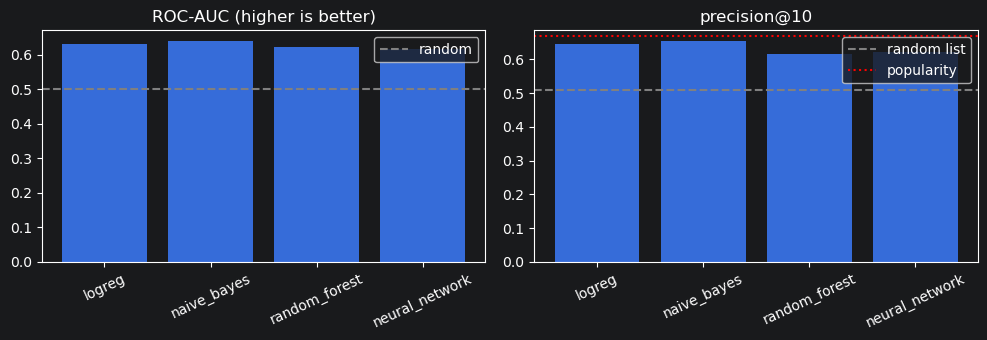

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].bar(summary.index, summary["auc"])
axes[0].axhline(0.5, color="gray", linestyle="--", label="random")
axes[0].set_title("ROC-AUC (higher is better)")
axes[0].legend()
axes[1].bar(summary.index, summary["p_at_k"])
axes[1].axhline(baselines["like_rate"], color="gray", linestyle="--", label="random list")
axes[1].axhline(baselines["pop_p_at_k"], color="red", linestyle=":", label="popularity")
axes[1].set_title("precision@10")
axes[1].legend()
for ax in axes:
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

**QUESTION 3.** Compare the models: which one has the best AUC and the best precision@10, and is the difference large compared with the spread between users (look at `results.groupby("model")["auc"].std()`)? Then compare accuracy with the majority-class baseline, and precision@10 with the popularity baseline. What do these comparisons say about content-based filtering built only from genres and decade?

**Your answer (Q3):**

Naive Bayes has the best mean AUC (0.639) and the best precision@10 (0.653), followed closely by logistic regression (0.632 and 0.645). Random forest and the neural network are slightly worse. The gap between the best and the worst model is only about 0.02 AUC. The standard deviation of AUC between users is about 0.09, four to five times larger. The result depends much more on which user we evaluate than on which model we choose. With 40 users, the difference between the models is not meaningful. With such simple features, a more complex model has nothing extra to learn.

The models reach 0.66–0.67 accuracy, while always predicting the majority class of the training set gives 0.646. That is a gain of only 2–3 points. Logistic regression beats this baseline for only 18 of the 40 users. Most of the accuracy comes from the class imbalance, not from what the model learned.

All models beat a random list on precision@10 (0.51), but none of them beats the popularity baseline (0.668). Recommending the most-rated movies, without any personalisation, gives a better top-10 than a personal classifier.

Content-based filtering built only from genres and decade gives a weak signal. An AUC of about 0.63 is only a little above random (0.5). The choice of model barely matters, because the features are the limit, not the model. Two things would help. One is richer item features, such as tags (see Q2). The other is information from other users, which is what makes the popularity baseline work and what collaborative filtering uses.